<center><a href="https://www.nvidia.com/dli"> <img src="https://raw.githubusercontent.com/NVDLI/fundamentals-of-deep-learning/main/course_content/tutorials/images/DLI_Header.png" alt="Header" style="width: 400px;"/> </a></center>

## License

Unless otherwise noted:

- Code cells are licensed under the
  [Apache License 2.0](../../LICENSES/Apache-2.0.txt).
- Markdown and raw cells are licensed under the
  [Creative Commons Attribution 4.0 International License](../../LICENSES/CC-BY-4.0.txt).
- Third-party material retains its original license and is identified in
  [`THIRD_PARTY_NOTICES.md`](../../THIRD_PARTY_NOTICES.md).

Copyright (c) 2026 NVIDIA CORPORATION & AFFILIATES.

# 2. Image Classification of an American Sign Language Dataset

In this section, we will perform the data preparation, model creation, and model training steps we observed in the last section using a different dataset: images of hands making letters in [American Sign Language](http://www.asl.gs/).

## 2.1 Setup for Google Colab

**Only run this cell if you are using Google Colab.** In other environments, skip it and continue with the lesson.

In [1]:
%%bash
# @title Setup for Google Colab { display-mode: "form" }
# @markdown **Only run this cell if you are using Google Colab.** Otherwise, skip it. Select a GPU under **Runtime → Change runtime type** before running it.
set -e

# Skip setup outside Google Colab.
if [ -z "${COLAB_RELEASE_TAG:-}${COLAB_BACKEND_VERSION:-}" ]; then
    exit 0
fi

# Download only the support files used by this lab.
course_url=https://raw.githubusercontent.com/NVDLI/fundamentals-of-deep-learning/main/course_content

# Download only this lab's support files; preserve existing files and student work.
for course_file in data/data.py; do
    if [ ! -e "$course_file" ]; then
        mkdir -p "$(dirname "$course_file")"
        curl -fsSL "$course_url/tutorials/$course_file" -o "$course_file.download"
        mv "$course_file.download" "$course_file"
    fi
done

# Install only this lab's packages that are missing from the current runtime.
missing_packages=()
for course_package in torch numpy pandas matplotlib pillow datasets kagglehub; do
    if ! pip show "$course_package" >/dev/null 2>&1; then
        missing_packages+=("$course_package")
    fi
done
if [ "${#missing_packages[@]}" -gt 0 ]; then
    pip install --quiet "${missing_packages[@]}"
fi

echo "Course ready. Continue with the next cell."


Course ready. Continue with the next cell.


## 2.1 Objectives

* Prepare image data for training
* Create and compile a simple model for image classification
* Train an image classification model and observe the results

In [2]:
import torch.nn as nn
import pandas as pd
import torch
from torch.optim import Adam
from torch.utils.data import Dataset, DataLoader

from data.data import download_asl_dataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.cuda.is_available()

True

## 2.2 American Sign Language Dataset

The [American Sign Language alphabet](http://www.asl.gs/) contains 26 letters. Two of those letters (j and z) require movement, so they are not included in the training dataset.  

<img src="https://raw.githubusercontent.com/NVDLI/fundamentals-of-deep-learning/main/course_content/tutorials/images/asl.png" style="width: 600px;">

### 2.2.1 HuggingFace

This dataset is available on [HuggingFace Hub](https://huggingface.co/datasets/juanjodurillo/asl-hg), a public repository for machine learning datasets and models. No account or API token is required to download it. It is mirror of the [ASL-HG: American Sign Language Hand Gesture Image Dataset](https://data.mendeley.com/datasets/j4y5w2c8w9/1) by Md. Famidul Islam Pranto, Md. Rifatul Islam, Md. Ali Akbor, Nabonita Ghosh, Md. Rahatun Alam, Sudipto Chaki, Md Masudul Islam

The helper function `download_asl_dataset()` in `data/data.py` downloads the dataset automatically the first time it is called, converts each image to a 28×28 grayscale representation, and caches the results as CSV files so that subsequent calls load from disk instantly.

*Running this code will automatically download data from https://huggingface.co/datasets/juanjodurillo/asl-hg. Before you run the code, please confirm the content of the dataset and licensing is appropriate for your intended use*

In [3]:
download_asl_dataset()

README.md:   0%|          | 0.00/1.79k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  301MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 74.6MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/28800 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7200 [00:00<?, ? examples/s]

Processing train (28,800 images) …
  19,200 rows saved → 'data/asl_data/sign_mnist_train.csv'
Processing test (7,200 images) …
  4,800 rows saved → 'data/asl_data/sign_mnist_valid.csv'
Dataset ready.


(       label  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  \
 0          0     233     235     235     233     233     233     233     233   
 1          0     231     231     231     230     230     230     230     231   
 2          0     232     233     233     232     232     232     232     232   
 3          0     232     233     232     232     232     232     232     232   
 4          0     232     233     233     232     232     232     232     233   
 ...      ...     ...     ...     ...     ...     ...     ...     ...     ...   
 19195     23     220     222     222     221     221     221     219     218   
 19196     23     220     221     221     220     220     221     218     216   
 19197     23     219     220     220     220     220     221     219     217   
 19198     23     219     221     221     221     220     220     219     217   
 19199     23     219     221     221     220     220     220     219     216   
 
        pixel9  ...  pixel

## 2.3 Loading the Data

This dataset is not available via TorchVision in the same way that MNIST is, so let's learn how to load custom data. By the end of this section we will have `x_train`, `y_train`, `x_valid`, and `y_valid` variables.

### 2.3.1 Reading in the Data

The sign language dataset is in [CSV](https://en.wikipedia.org/wiki/Comma-separated_values) (Comma Separated Values) format, the same data structure behind Microsoft Excel and Google Sheets. It is a grid of rows and columns with labels at the top, as seen in the [train](data/asl_data/sign_mnist_train.csv) and [valid](data/asl_data/sign_mnist_valid.csv) datasets (they may take a moment to load).

To load and work with the data, we'll be using a library called [Pandas](https://pandas.pydata.org/), which is a highly performant tool for loading and manipulating data. We'll read the CSV files into a format called a [DataFrame](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.html).

Pandas has a [read_csv](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_csv.html) method that expects a csv file, and returns a DataFrame:

In [4]:
train_df, valid_df = download_asl_dataset()
train_df.head()

Loading cached dataset from 'data/asl_data' …


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,233,235,235,233,233,233,233,233,234,...,204,230,228,228,230,231,230,228,229,228
1,0,231,231,231,230,230,230,230,231,232,...,65,189,232,227,228,228,227,228,230,230
2,0,232,233,233,232,232,232,232,232,232,...,199,231,229,230,231,232,229,228,229,229
3,0,232,233,232,232,232,232,232,232,233,...,202,231,229,230,231,232,230,228,229,228
4,0,232,233,233,232,232,232,232,233,233,...,207,230,228,229,231,231,230,229,230,228


### 2.3.2 Exploring the Data

Let's take a look at our data. We can use the [head](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.head.html) method to print the first few rows of the DataFrame. Each row is an image which has a `label` column, and also, 784 values representing each pixel value in the image, just like with the MNIST dataset. Note that the labels currently are numerical values, not letters of the alphabet:

In [5]:
train_df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,233,235,235,233,233,233,233,233,234,...,204,230,228,228,230,231,230,228,229,228
1,0,231,231,231,230,230,230,230,231,232,...,65,189,232,227,228,228,227,228,230,230
2,0,232,233,233,232,232,232,232,232,232,...,199,231,229,230,231,232,229,228,229,229
3,0,232,233,232,232,232,232,232,232,233,...,202,231,229,230,231,232,230,228,229,228
4,0,232,233,233,232,232,232,232,233,233,...,207,230,228,229,231,231,230,229,230,228


### 2.3.3 Extracting the Labels

Let's store our training and validation labels in `y_train` and `y_valid` variables. We can use the [pop](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pop.html) method to remove a column from our DataFrame and assign the removed values to a variable.

In [6]:
y_train = train_df.pop('label')
y_valid = valid_df.pop('label')
y_train

,label
0,0
1,0
2,0
3,0
4,0
...,...
19195,23
19196,23
19197,23
19198,23


### 2.3.4 Extracting the Images

Next, let's store our training and validation images in `x_train` and `x_valid` variables. Here we create those variables:

In [7]:
x_train = train_df.values
x_valid = valid_df.values
x_train

array([[233, 235, 235, ..., 228, 229, 228],
       [231, 231, 231, ..., 228, 230, 230],
       [232, 233, 233, ..., 228, 229, 229],
       ...,
       [219, 220, 220, ..., 172, 175, 197],
       [219, 221, 221, ..., 172, 175, 198],
       [219, 221, 221, ..., 172, 175, 197]], shape=(19200, 784))

### 2.3.5 Summarizing the Training and Validation Data

We now have 19,200 images with 784 pixels each for training...

In [8]:
x_train.shape

(19200, 784)

...as well as their corresponding labels:

In [9]:
y_train.shape

(19200,)

For validation, we have 4,800 images...

In [10]:
x_valid.shape

(4800, 784)

...and their corresponding labels:

In [11]:
y_valid.shape

(4800,)

## 2.4 Visualizing the Data

To visualize the images, we will again use the matplotlib library. We don't need to worry about the details of this visualization, but if interested, you can learn more about [matplotlib](https://matplotlib.org/) at a later time.

Note that we'll have to reshape the data from its current 1D shape of 784 pixels, to a 2D shape of 28x28 pixels to make sense of the image:

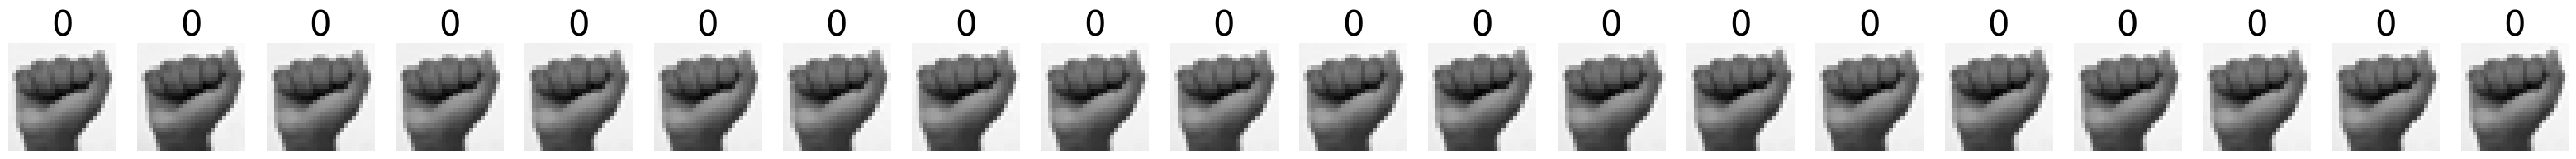

In [12]:
import matplotlib.pyplot as plt
plt.figure(figsize=(40,40))

num_images = 20
for i in range(num_images):
    row = x_train[i]
    label = y_train[i]

    image = row.reshape(28,28)
    plt.subplot(1, num_images, i+1)
    plt.title(label, fontdict={'fontsize': 30})
    plt.axis('off')
    plt.imshow(image, cmap='gray')

### 2.4.1 Normalize the Image Data

As we did with the MNIST dataset, we are going to normalize the image data, meaning that their pixel values, instead of being between 0 and 255 as they are currently:

In [13]:
x_train.min()

np.int64(0)

In [14]:
x_train.max()

np.int64(255)

In the previous lab, we used [ToTensor](https://pytorch.org/vision/main/generated/torchvision.transforms.ToTensor.html), but we can also modify our data before turning it into a tensor.

In [15]:
x_train = train_df.values / 255
x_valid = valid_df.values / 255

### 2.4.2 Custom Datasets

We can use PyTorch's [Dataset](https://pytorch.org/tutorials/beginner/basics/data_tutorial.html) tools in order to create our own dataset. `__init__` will run once when the class is initialized. `__getitem__` returns our images and labels.

Since our dataset is small enough, we can store it on our GPU for faster processing. In the previous lab, we sent our data to the GPU when it was drawn from each batch. Here, we will send it to the GPU in the `__init__` function.

In [16]:
class MyDataset(Dataset):
    def __init__(self, x_df, y_df):
        self.xs = torch.tensor(x_df).float().to(device)
        self.ys = torch.tensor(y_df).to(device)

    def __getitem__(self, idx):
        x = self.xs[idx]
        y = self.ys[idx]
        return x, y

    def __len__(self):
        return len(self.xs)

A custom PyTorch dataset works just like a prebuilt one. It should be passed to a [DataLoader](https://pytorch.org/tutorials/beginner/basics/data_tutorial.html#preparing-your-data-for-training-with-dataloaders) for model training.

In [17]:
BATCH_SIZE = 32

train_data = MyDataset(x_train, y_train)
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
train_N = len(train_loader.dataset)

In [18]:
valid_data = MyDataset(x_valid, y_valid)
valid_loader = DataLoader(valid_data, batch_size=BATCH_SIZE)
valid_N = len(valid_loader.dataset)

We can verify the DataLoader works as expected with the code below. We'll make the DataLoader [iterable](https://docs.python.org/3/library/functions.html#iter), and then call [next](https://docs.python.org/3/library/functions.html#next) to draw the first hand from the deck.

In [19]:
train_loader

Try running the below a few times. The values should change each time.

In [20]:
batch = next(iter(train_loader))
batch

[tensor([[0.8353, 0.8392, 0.8392,  ..., 0.8431, 0.8471, 0.8471],
         [0.7255, 0.7373, 0.7412,  ..., 0.5137, 0.5137, 0.5137],
         [0.8863, 0.8863, 0.8863,  ..., 0.2314, 0.2549, 0.5216],
         ...,
         [0.9255, 0.9294, 0.9294,  ..., 0.9059, 0.9059, 0.9059],
         [0.7569, 0.7529, 0.7529,  ..., 0.6745, 0.6667, 0.6627],
         [0.8980, 0.8941, 0.9020,  ..., 0.1765, 0.1922, 0.2471]],
        device='cuda:0'),
 tensor([ 2, 15, 12, 17, 13, 15,  7, 15, 15, 15,  7, 21,  4, 22,  9, 10, 18,  5,
         14,  2, 23, 10, 13,  7,  3, 22, 20, 15, 10,  0,  0, 21],
        device='cuda:0')]

Notice the batch has two values. The first is our `x`, and the second is our `y`. The first dimension of each should have `32` values, which is the `batch_size`.

In [21]:
batch[0].shape

torch.Size([32, 784])

In [22]:
batch[1].shape

torch.Size([32])

## 2.5 Build the Model

We've created our DataLoaders, now it's time to build our models.

#### Exercise

For this exercise we are going to build a sequential model. Just like last time, build a model that:

* Has a flatten layer.
* Has a dense input layer. This layer should contain 512 neurons amd use the `relu` activation function
* Has a second dense layer with 512 neurons which uses the `relu` activation function
* Has a dense output layer with neurons equal to the number of classes

We will define a few variables to get started:

In [23]:
input_size = 28 * 28
n_classes = 24

Do your work in the cell below, creating a `model` variable to store the model. We've imported the [Sequental](https://pytorch.org/docs/stable/generated/torch.nn.Sequential.html) model class and [Linear](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html) layer class to get you started. Reveal the solution below for a hint:

In [24]:
model = nn.Sequential(

)

#### Solution

In [25]:
# SOLUTION
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(input_size, 512),  # Input
    nn.ReLU(),  # Activation for input
    nn.Linear(512, 512),  # Hidden
    nn.ReLU(),  # Activation for hidden
    nn.Linear(512, n_classes)  # Output
)

This time, we'll combine compiling the model and sending it to the GPU in one step:

In [26]:
model = torch.compile(model.to(device))
model

OptimizedModule(
  (_orig_mod): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=512, bias=True)
    (4): ReLU()
    (5): Linear(in_features=512, out_features=24, bias=True)
  )
)

Since categorizing these ASL images is similar to categorizing MNIST's handwritten digits, we will use the same `loss_function` ([Categorical CrossEntropy](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)) and `optimizer` ([Adam](https://pytorch.org/docs/stable/generated/torch.optim.Adam.html)). `nn.CrossEntropyLoss` includes the softmax function, and is computationally faster when passing class indices as opposed to predicted probabilities.

In [27]:
loss_function = nn.CrossEntropyLoss()
optimizer = Adam(model.parameters())

## 2.6 Training the Model

This time, let's look at our `train` and `validate` functions in more detail.

### 2.6.1 The Train Function

This code is almost the same as in the previous notebook, but we no longer send `x` and `y` to our GPU because our DataLoader already does that.

Before looping through the DataLoader, we will set the model to [model.train](https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.train) to make sure its parameters can be updated. To make it easier for us to follow training progress, we'll keep track of the total `loss` and `accuracy`.

Then, for each batch in our `train_loader`, we will:
1. Get an `output` prediction from the model
2. Set the gradient to zero with the `optimizer`'s [zero_grad](https://pytorch.org/docs/stable/generated/torch.optim.Optimizer.zero_grad.html) function
3. Calculate the loss with our `loss_function`
4. Compute the gradient with [backward](https://pytorch.org/docs/stable/generated/torch.Tensor.backward.html)
5. Update our model parameters with the `optimizer`'s [step](https://pytorch.org/docs/stable/generated/torch.optim.Optimizer.step.html) function.
6. Update the `loss` and `accuracy` totals

In [28]:
def train():
    loss = 0
    accuracy = 0

    model.train()
    for x, y in train_loader:
        output = model(x)
        optimizer.zero_grad()
        batch_loss = loss_function(output, y)
        batch_loss.backward()
        optimizer.step()

        loss += batch_loss.item()
        accuracy += get_batch_accuracy(output, y, train_N)
    print('Train - Loss: {:.4f} Accuracy: {:.4f}'.format(loss, accuracy))

### 2.6.2 The Validate Function

The model does not learn during validation, so the `validate` function is simpler than the `train` function above.

One key difference is we will set the model to evaluation mode with [model.evaluate](https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.eval), which will prevent the model from updating any parameters.

In [29]:
def validate():
    loss = 0
    accuracy = 0

    model.eval()
    with torch.no_grad():
        for x, y in valid_loader:
            output = model(x)

            loss += loss_function(output, y).item()
            accuracy += get_batch_accuracy(output, y, valid_N)
    print('Valid - Loss: {:.4f} Accuracy: {:.4f}'.format(loss, accuracy))

### 2.6.3 Calculating the Accuracy

Both the `train` and `validate` functions use `get_batch_accuracy`, but we have not defined that in this notebook yet.

#### Exercise

The function below has three `FIXME`s. Each one corresponds to the functions input arguments. Can you replace each FIXME with the correct argument?

It may help to view the documentation for [argmax](https://pytorch.org/docs/stable/generated/torch.argmax.html), [eq](https://pytorch.org/docs/stable/generated/torch.eq.html), and [view_as](https://pytorch.org/docs/stable/generated/torch.Tensor.view_as.html).

In [30]:
def get_batch_accuracy(output, y, N):
    pred = FIXME.argmax(dim=1, keepdim=True)
    correct = pred.eq(FIXME.view_as(pred)).sum().item()
    return correct / FIXME

#### Solution

Click the `...` below for the solution.

In [31]:
# SOLUTION
def get_batch_accuracy(output, y, N):
    pred = output.argmax(dim=1, keepdim=True)
    correct = pred.eq(y.view_as(pred)).sum().item()
    return correct / N

### 2.6.3 The Training Loop

Let's bring it all together! Run the cell below to train the data for 20 `epochs`.

In [32]:
epochs = 20

for epoch in range(epochs):
    print('Epoch: {}'.format(epoch))
    train()
    validate()

Epoch: 0


W1111 10:47:10.346000 551 torch/_inductor/utils.py:1806] [0/0] Not enough SMs to use max_autotune_gemm mode


Train - Loss: 617.1789 Accuracy: 0.6828
Valid - Loss: 41.2944 Accuracy: 0.9069
Epoch: 1
Train - Loss: 74.0842 Accuracy: 0.9689
Valid - Loss: 8.4441 Accuracy: 0.9885
Epoch: 2
Train - Loss: 29.7209 Accuracy: 0.9876
Valid - Loss: 1.2601 Accuracy: 0.9994
Epoch: 3
Train - Loss: 15.0262 Accuracy: 0.9944
Valid - Loss: 1.7446 Accuracy: 0.9981
Epoch: 4
Train - Loss: 23.8664 Accuracy: 0.9884
Valid - Loss: 0.3662 Accuracy: 0.9998
Epoch: 5
Train - Loss: 19.1022 Accuracy: 0.9904
Valid - Loss: 12.1516 Accuracy: 0.9752
Epoch: 6
Train - Loss: 22.4770 Accuracy: 0.9891
Valid - Loss: 0.1972 Accuracy: 0.9998
Epoch: 7
Train - Loss: 7.7543 Accuracy: 0.9959
Valid - Loss: 0.1022 Accuracy: 0.9998
Epoch: 8
Train - Loss: 7.9528 Accuracy: 0.9962
Valid - Loss: 14.3970 Accuracy: 0.9729
Epoch: 9
Train - Loss: 36.1989 Accuracy: 0.9820
Valid - Loss: 6.8581 Accuracy: 0.9888
Epoch: 10
Train - Loss: 2.8791 Accuracy: 0.9989
Valid - Loss: 0.1296 Accuracy: 0.9998
Epoch: 11
Train - Loss: 0.4873 Accuracy: 0.9999
Valid - Loss:

### 2.6.4 Discussion: What happened?

We can see that the training accuracy got to a fairly high level, but the validation accuracy was not as high. What happened here?

Think about it for a bit before clicking on the '...' below to reveal the answer.

`# SOLUTION`
This is an example of the model learning to categorize the training data, but performing poorly against new data that it has not been trained on. Essentially, it is memorizing the dataset, but not gaining a robust and general understanding of the problem. This is a common issue called *overfitting*. We will discuss overfitting in the next two lectures, as well as some ways to address it.

## 2.7 Summary

In this section you built your own neural network to perform image classification that is quite accurate. Congrats!

At this point we should be getting somewhat familiar with the process of loading data (including labels), preparing it, creating a model, and then training the model with prepared data.

### 2.7.1 Clear the Memory
Before moving on, please execute the following cell to clear up the GPU memory. This is required to move on to the next notebook.

In [33]:
import IPython
app = IPython.Application.instance()
app.kernel.do_shutdown(True)

{'status': 'ok', 'restart': True}

### 2.7.2 Next

Now that you have built some very basic, somewhat effective models, we will begin to learn about more sophisticated models, including *Convolutional Neural Networks*.

<center><a href="https://www.nvidia.com/dli"> <img src="https://raw.githubusercontent.com/NVDLI/fundamentals-of-deep-learning/main/course_content/tutorials/images/DLI_Header.png" alt="Header" style="width: 400px;"/> </a></center>